In [1]:
from itertools import product
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt
import seaborn as sns
import h5py
# import fastplotlib as fpl

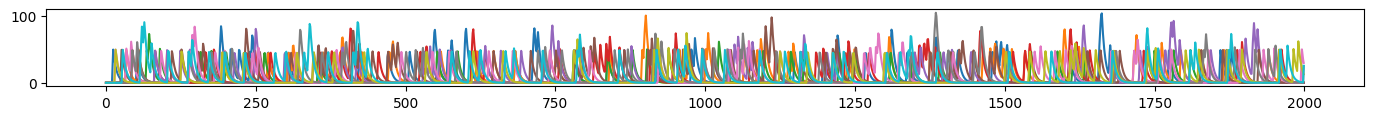

<Axes: >

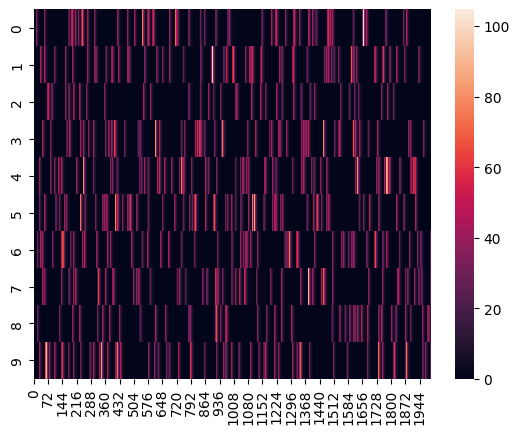

In [2]:
n_timepoints = 1_000
n_pixels = 3
n_components = 10
interp_factor = 2

clean = np.zeros((n_components, n_timepoints * interp_factor))

x = 0
a = 0.7

b = 0

firing_prop = 0.05

spikes = list()

for i in range(n_components):
    spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

for c_ix in range(n_components):
    for i in range(2, n_timepoints):
        clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

    x_ = np.arange(0, n_timepoints * interp_factor)
    xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
    clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

n_timepoints *= 2

fig = plt.figure(figsize=(17, 1))
for i in range(n_components):
    plt.plot(clean[i])

plt.show()

sns.heatmap(clean)

In [3]:
f = h5py.File("./toy_data/ar_data", mode="w")

In [4]:
f["clean"] = clean

In [5]:
f["clean"].attrs["a"] = 0.7
f["clean"].attrs["firing_prob"] = 0.05
f["spikes"] = np.vstack(spikes)

In [6]:
f.create_group("noise")
f["noise"].create_group("gaussian")
f["noise"].create_group("poisson")

<HDF5 group "/noise/poisson" (0 members)>

In [7]:
noise_sigmas = np.arange(1, 30, 2)

series = list()

for n in noise_sigmas:
    f["noise"]["gaussian"][str(n)] = np.vstack([np.random.normal(scale=n, size=n_timepoints) for _ in range(n_components * n_pixels)])

In [9]:
sorted(f["noise"]["gaussian"].keys())

['1',
 '11',
 '13',
 '15',
 '17',
 '19',
 '21',
 '23',
 '25',
 '27',
 '29',
 '3',
 '5',
 '7',
 '9']

In [10]:
noise_lambdas = np.arange(1, 100, 5)
poisson_noise = np.zeros((noise_lambdas.size, n_components * n_pixels, n_timepoints))

In [11]:
noise_lambdas = np.arange(1, 100, 5)
for n in noise_lambdas:
    f["noise"]["poisson"][str(n)] = np.vstack([np.random.poisson(lam=n, size=n_timepoints) for _ in range(n_components * n_pixels)])

In [12]:
sorted(f["noise"]["poisson"].keys())

['1',
 '11',
 '16',
 '21',
 '26',
 '31',
 '36',
 '41',
 '46',
 '51',
 '56',
 '6',
 '61',
 '66',
 '71',
 '76',
 '81',
 '86',
 '91',
 '96']

In [13]:
f.close()

In [15]:
f = h5py.File("./toy_data/ar_data", mode="r")

In [5]:
n_pixels = 3

series = list()

for i in range(n_components):
    for j in range(n_pixels):
        noisy = clean[i] + np.random.normal(scale=noise, size=n_timepoints)
        noisy -= noisy.mean()
        series.append(noisy)

series = np.vstack(series)

<Axes: >

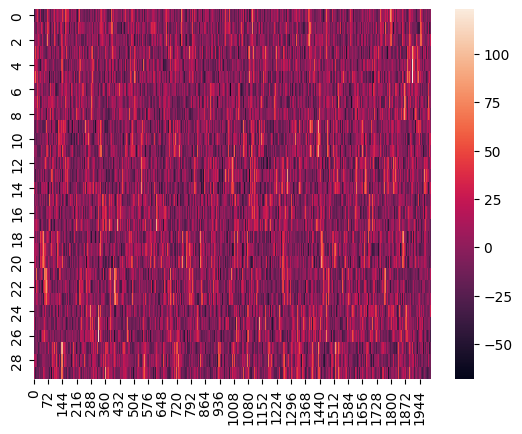

In [6]:
sns.heatmap(series)

In [7]:
series[-1] = np.random.normal(scale=noise, size=n_timepoints)
series[-1] -= series[-1].mean()

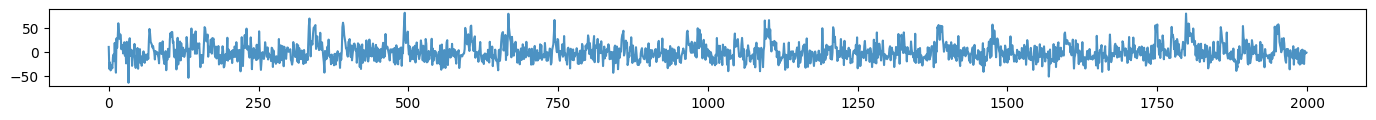

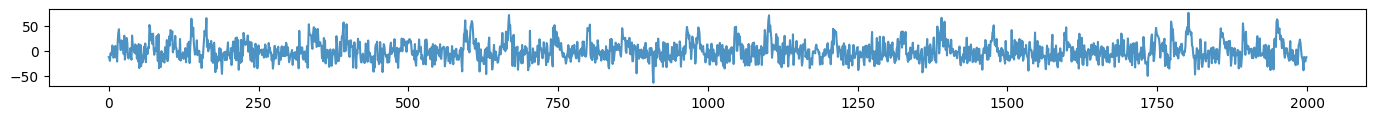

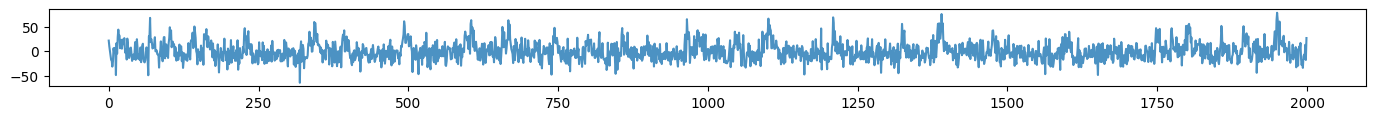

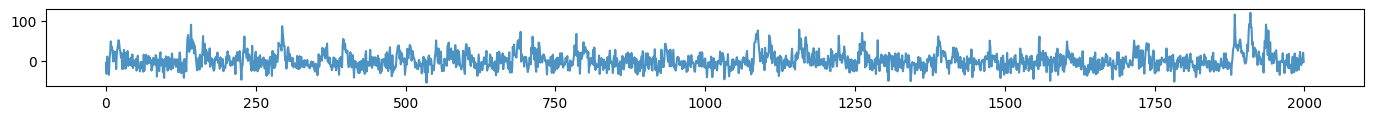

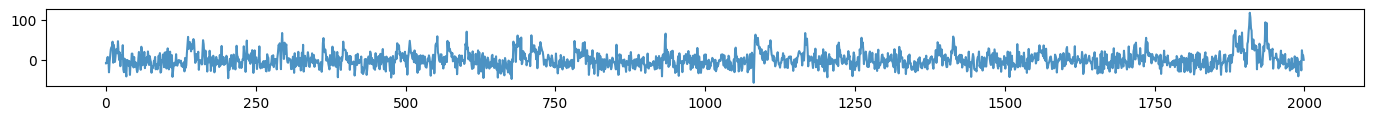

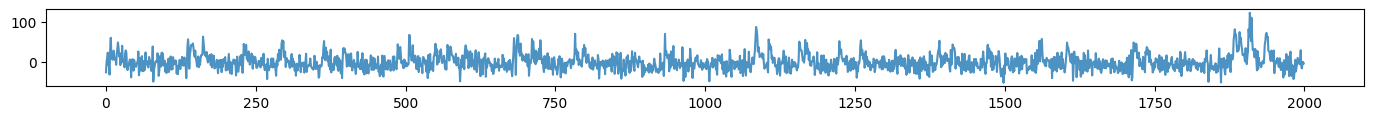

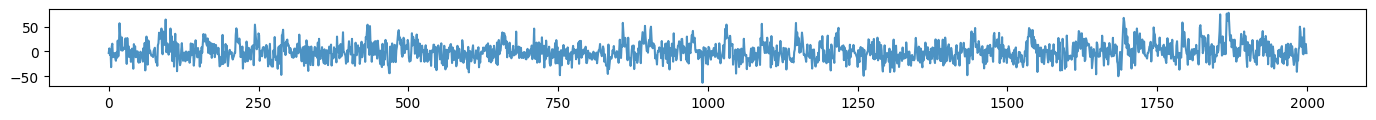

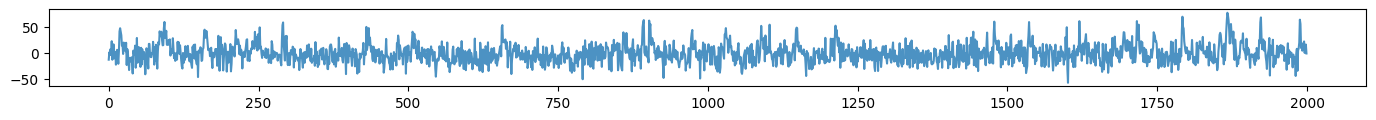

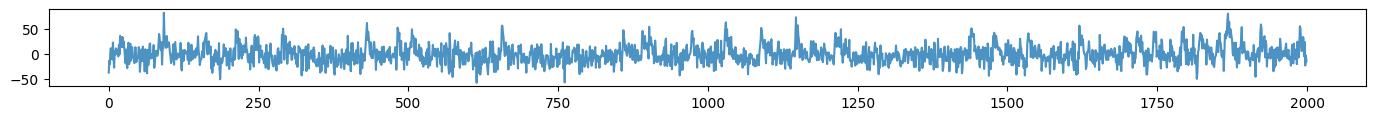

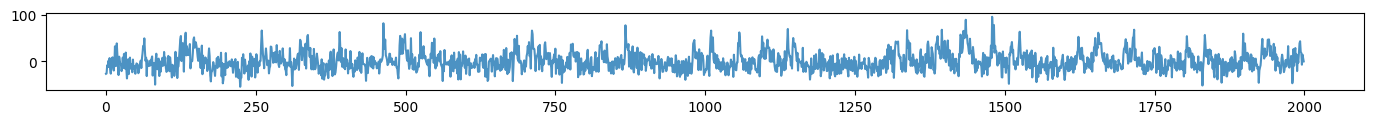

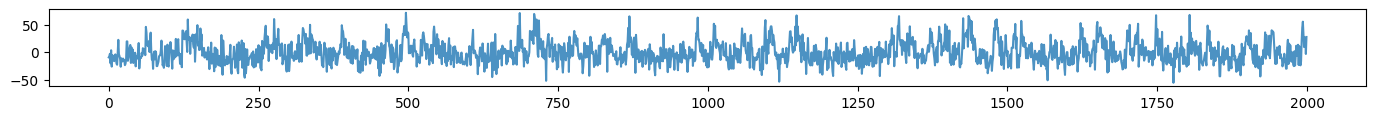

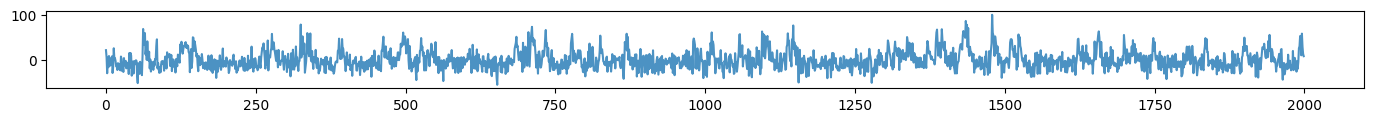

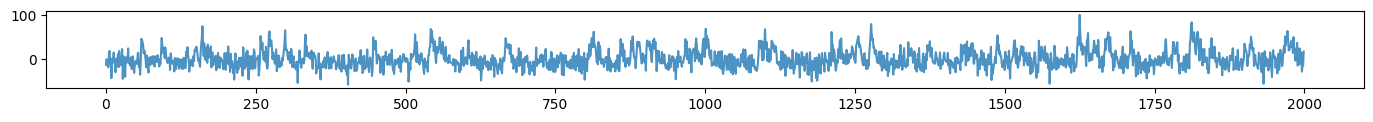

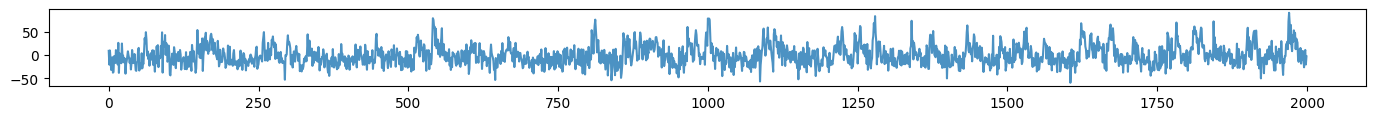

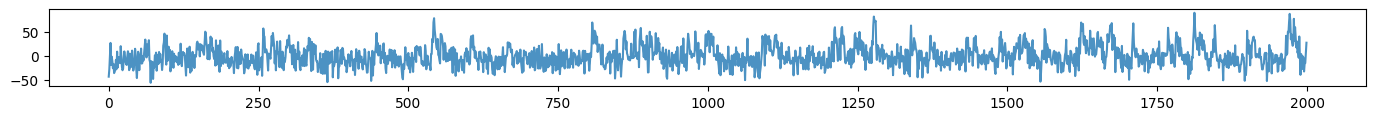

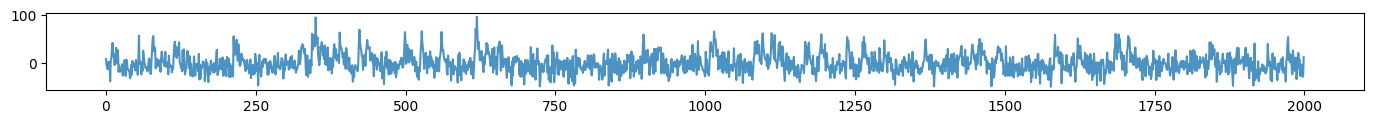

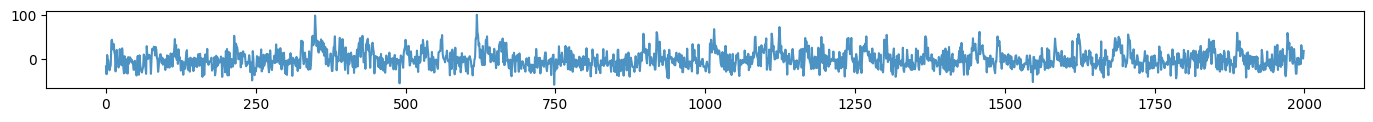

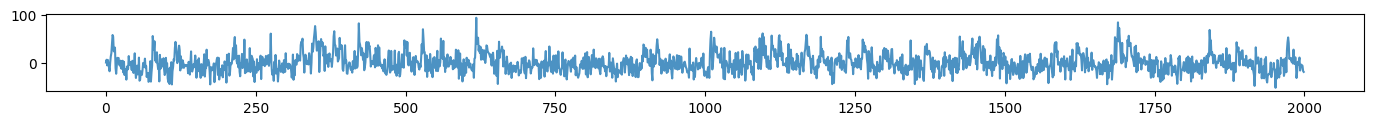

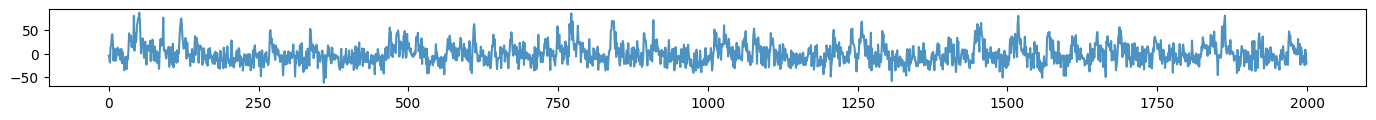

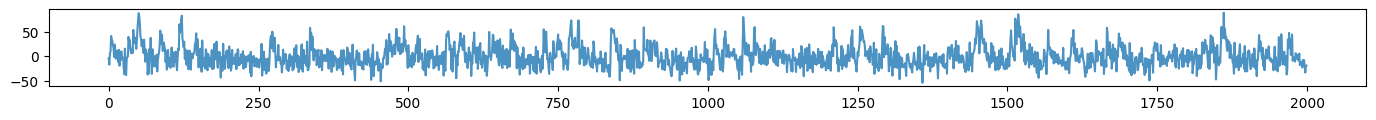

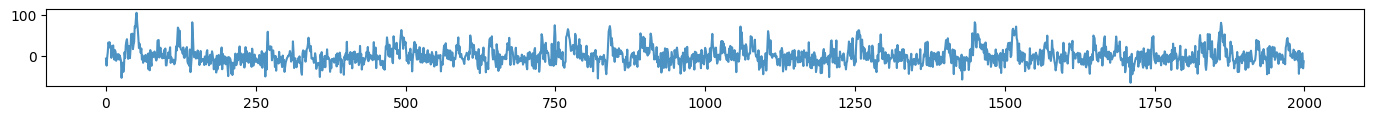

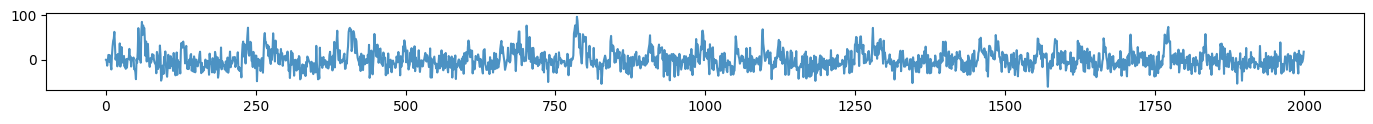

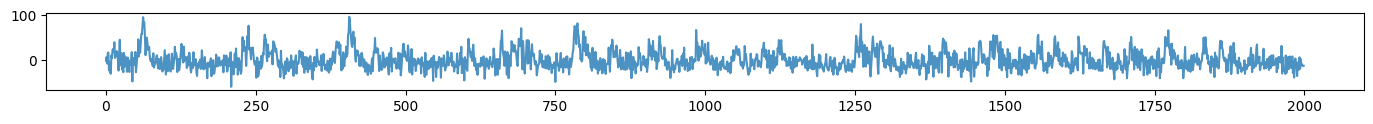

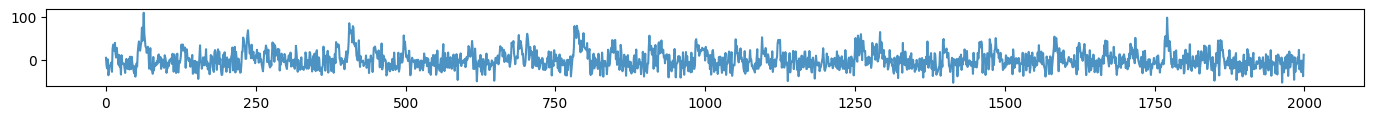

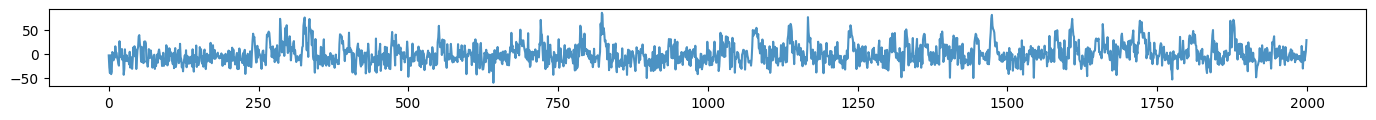

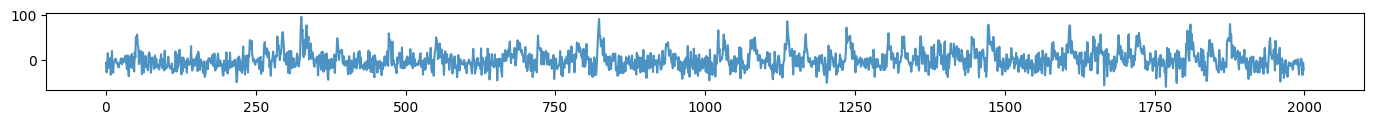

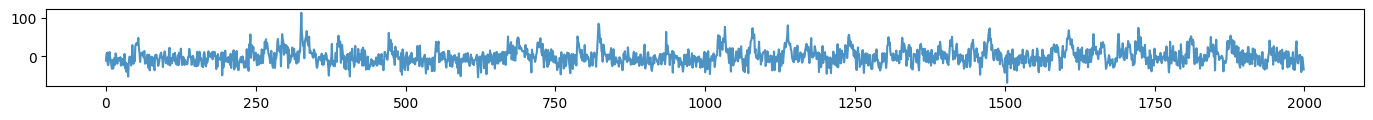

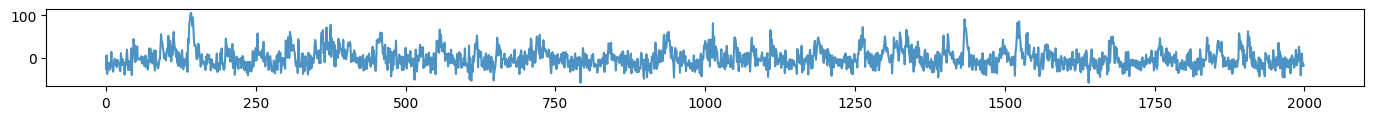

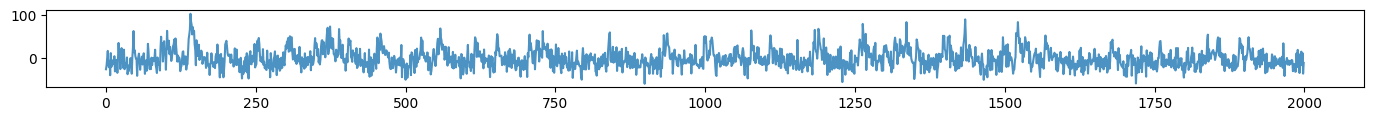

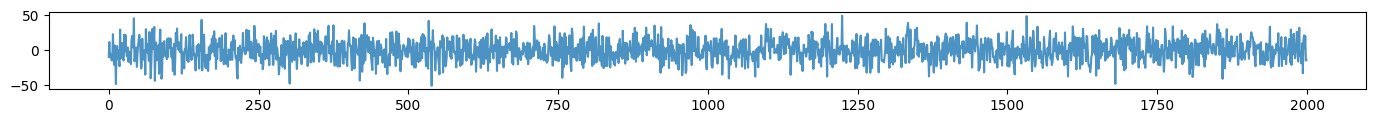

In [8]:
for i in range(n_pixels * n_components):
    fig = plt.figure(figsize=(17, 1))
    plt.plot(series[i], alpha=0.8)
    plt.show()

# plt.plot(clean, c="k", alpha=0.3)

In [12]:
def plot_regular_svd(Y):
    u, s, v = linalg.svd(Y)

    fig = plt.figure(figsize=(5, 2))
    plt.plot(s)
    plt.title("S")
    plt.show()
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    sns.heatmap(u, ax=axs[0])
    axs[0].set_title("U")
    sns.heatmap(v[:10], ax=axs[1])
    axs[1].set_title("V")
    plt.show()
    
    for i in range(n_components):
        fig = plt.figure(figsize=(20, 2))
        plt.plot(clean[i, :500], c="k")
        plt.twinx()
        plt.plot(v[i, :500])
    sns.heatmap(u[:, :10])
    plt.title("first 10 U")

    return v[0]

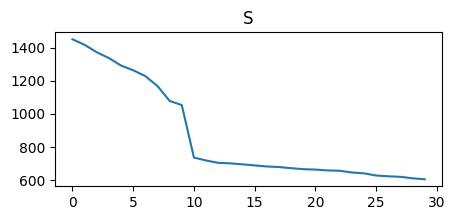

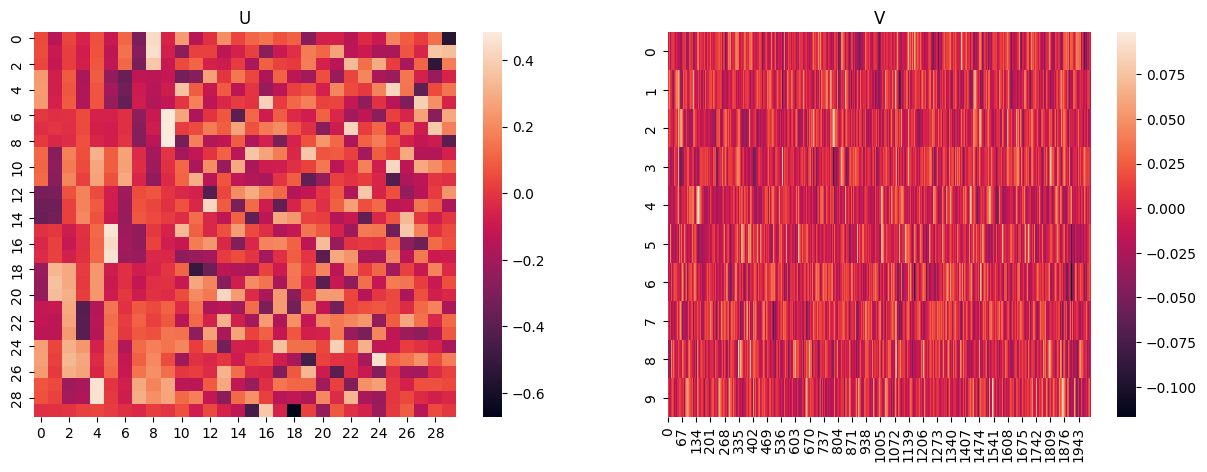

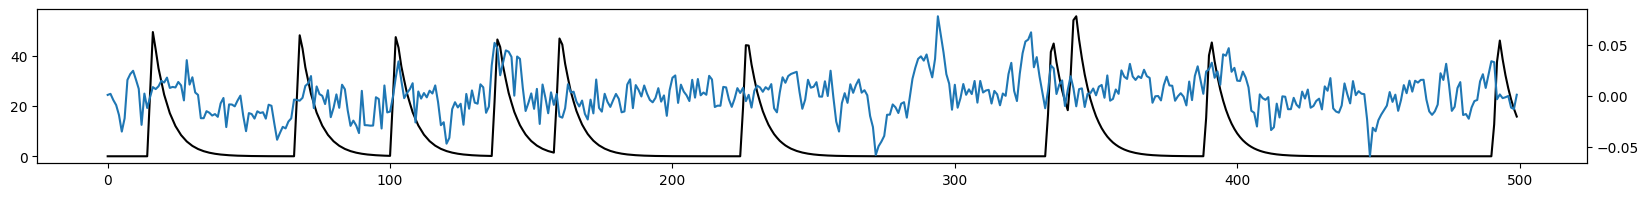

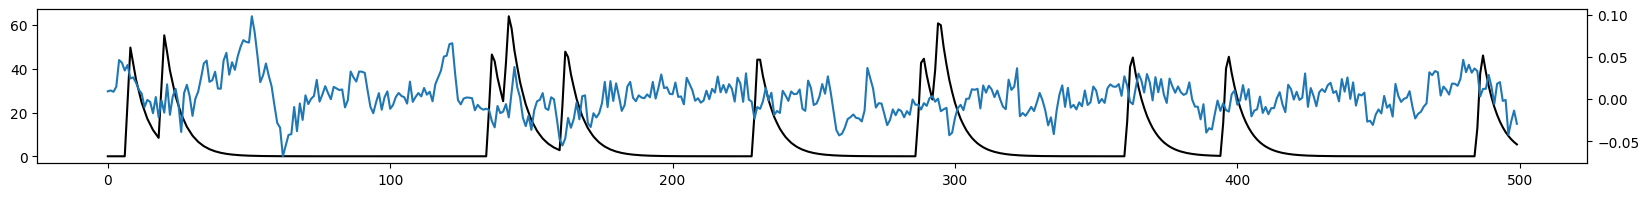

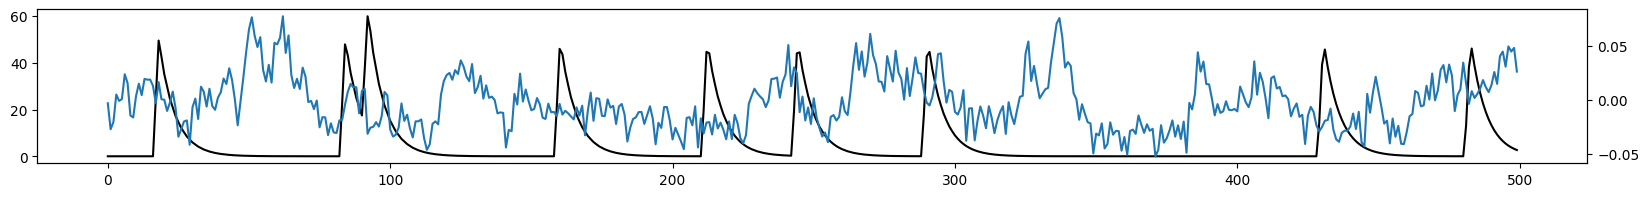

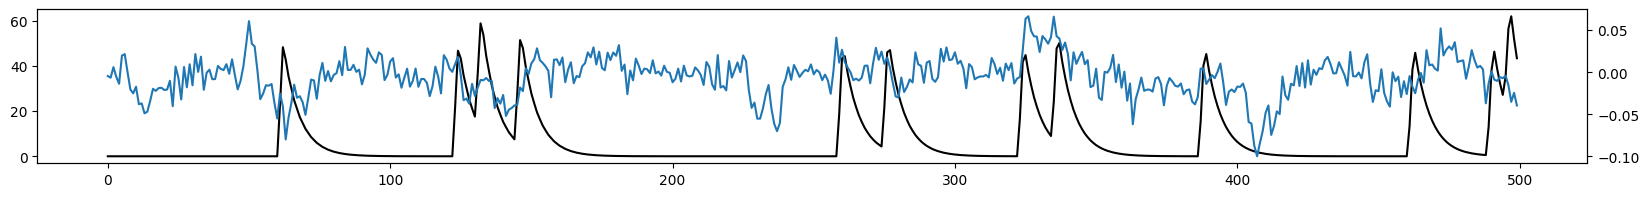

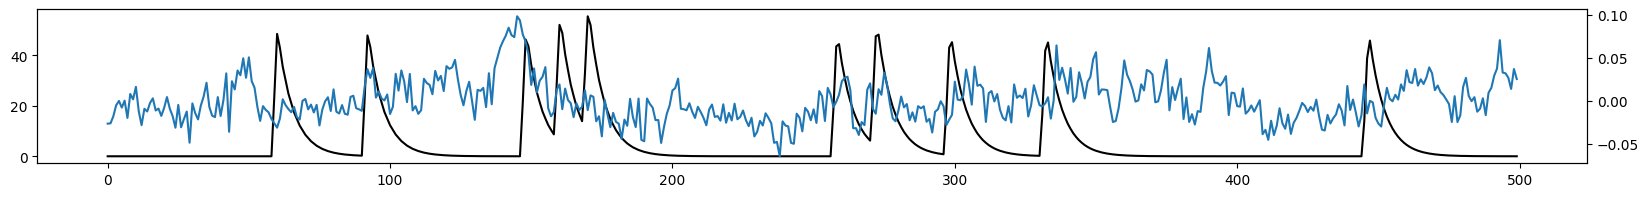

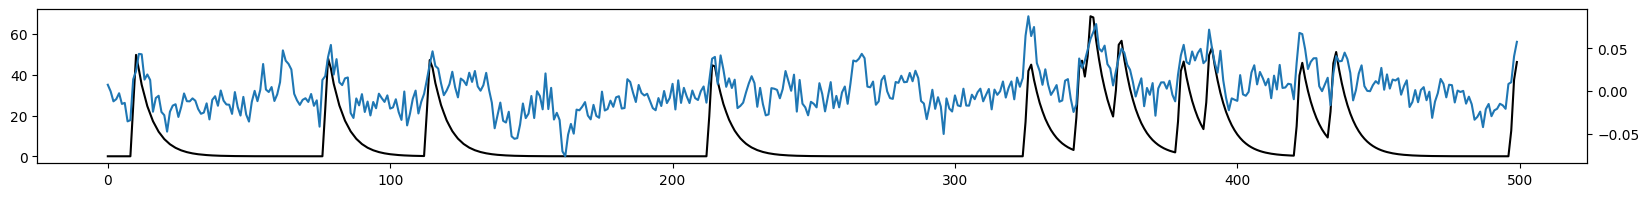

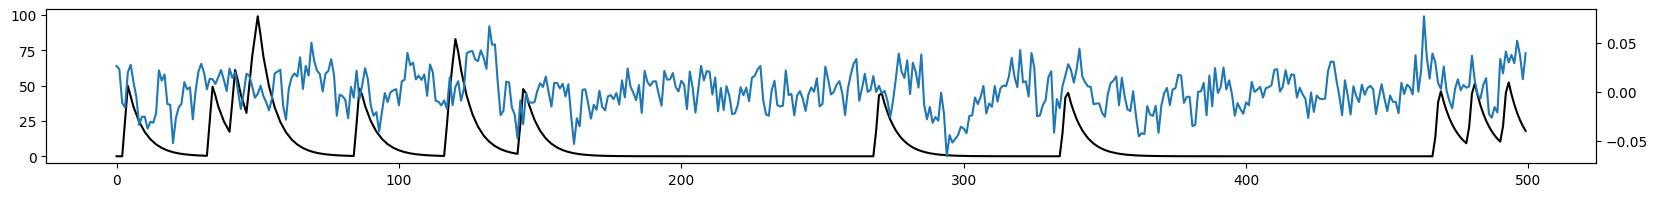

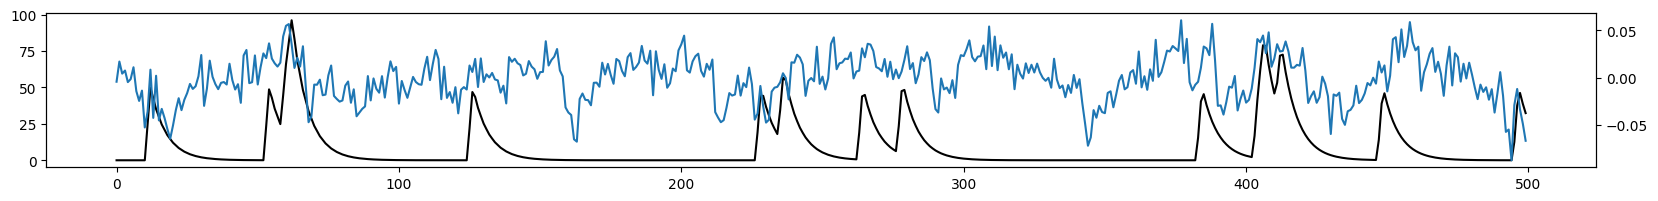

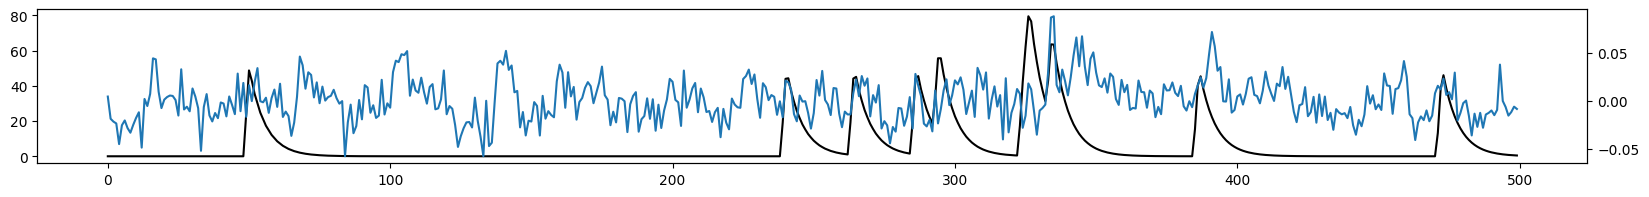

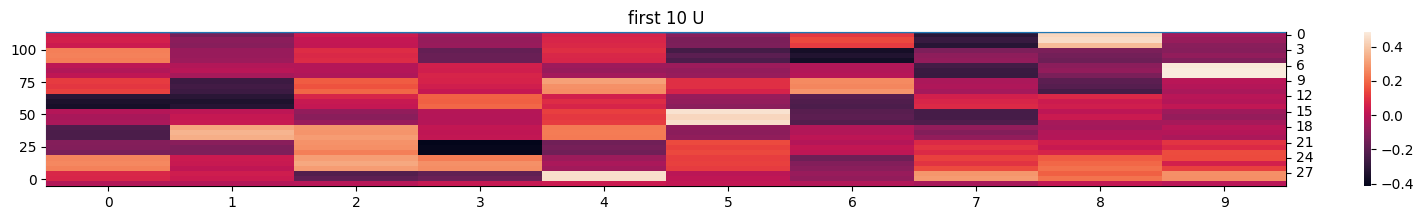

In [13]:
v0 = plot_regular_svd(series)

In [14]:
series.mean(axis=1)

array([ 5.68434189e-16,  4.83169060e-16, -4.26325641e-17,  1.42108547e-16,
       -1.70530257e-16, -3.12638804e-16,  3.41060513e-16, -2.27373675e-16,
       -1.13686838e-15,  3.41060513e-16, -2.04636308e-15,  0.00000000e+00,
        1.70530257e-15,  4.54747351e-16,  0.00000000e+00,  1.70530257e-16,
        5.68434189e-17, -9.09494702e-16,  1.73372428e-15, -8.52651283e-17,
        9.09494702e-16,  2.27373675e-16,  5.68434189e-16, -5.68434189e-16,
        9.09494702e-16, -9.09494702e-16,  1.13686838e-15,  1.36424205e-15,
        6.25277607e-16,  3.41060513e-16])

In [15]:
series.std(axis=1)

array([19.06689285, 19.08662002, 18.52673481, 20.92996652, 19.98891169,
       20.41837414, 18.36882059, 18.48978566, 18.795426  , 20.8575145 ,
       20.10108212, 20.8666804 , 21.03680243, 21.9623899 , 21.92859269,
       20.30648709, 19.94734709, 20.18505267, 21.47813401, 21.92241262,
       21.82169149, 21.25968311, 20.97463027, 21.03548332, 20.8632906 ,
       20.99873554, 20.83746266, 22.24664969, 22.12300671, 15.16322944])

In [16]:
series.ptp(axis=1)

array([147.09571052, 140.36687797, 141.81458767, 175.22485794,
       176.2310585 , 175.21075535, 140.14765434, 134.57875854,
       140.87640594, 150.28727814, 126.80436376, 155.73565745,
       160.88078126, 150.37626708, 144.54067736, 146.7548868 ,
       159.30278411, 145.98347238, 149.2269193 , 142.44469803,
       172.34327306, 157.49516401, 156.65350273, 163.81318322,
       144.4668734 , 156.07542254, 181.39790642, 163.87070528,
       162.53614418,  99.92696607])

In [17]:
from scipy import linalg

In [18]:
import seaborn as sns

/tmp/ipykernel_2862469/1268377926.py:28: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


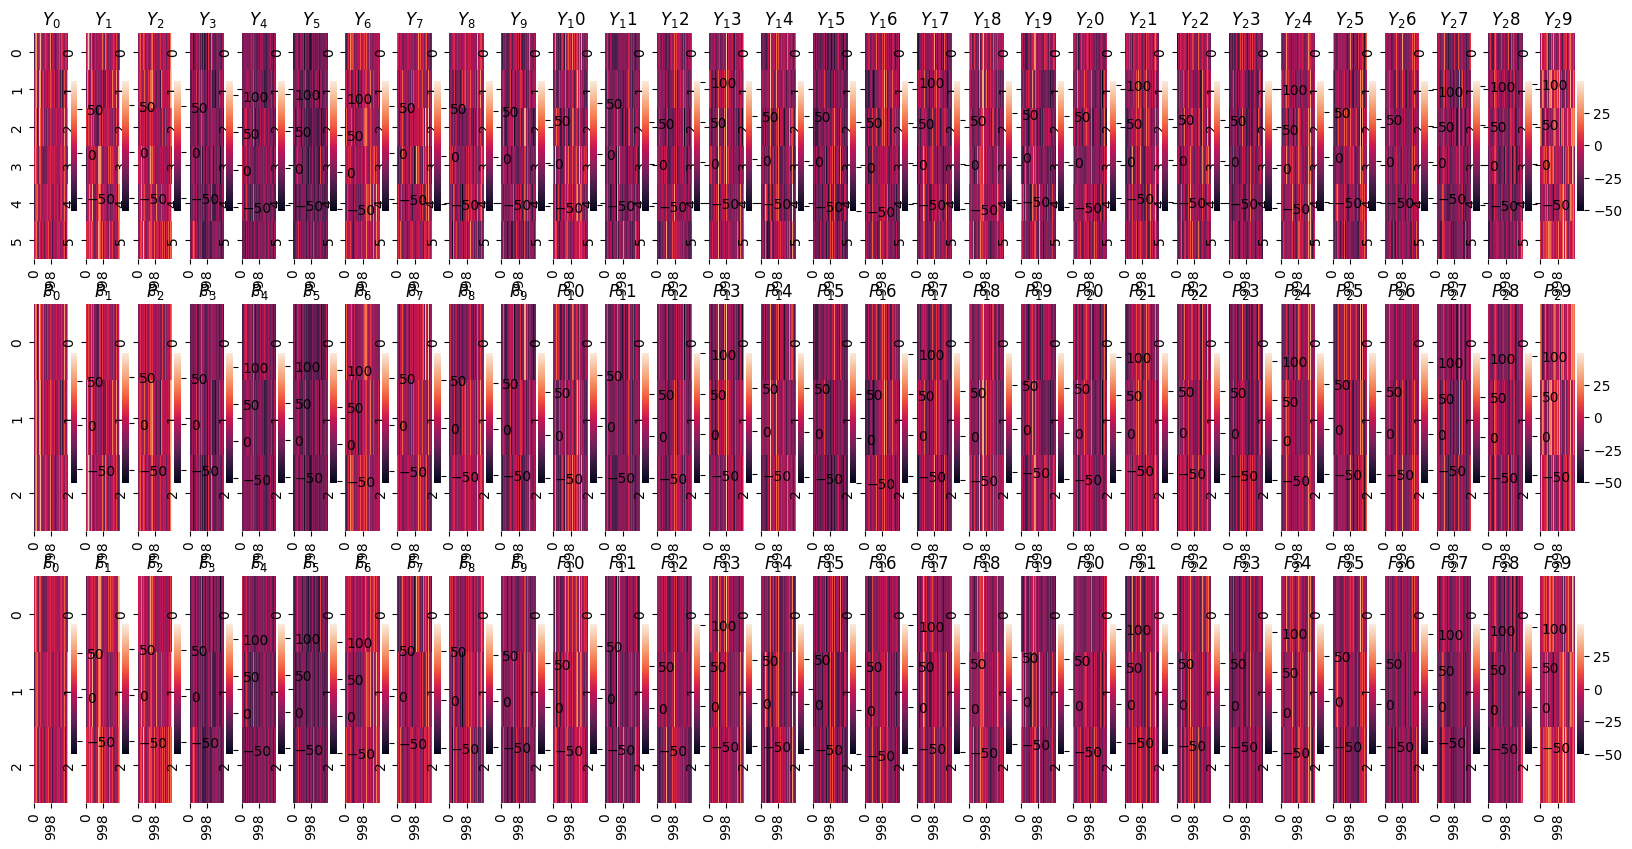

In [19]:
center = 100
w = 6

Ys = list()
Ps = list()
Fs = list()

fig, axs = plt.subplots(3, series.shape[0], figsize=(20, 10))

for i in range(series.shape[0]):
    y = linalg.hankel(series[i, :w], series[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)
        
    sns.heatmap(y, ax=axs[0, i])
    axs[0, i].set_title(f"$Y_{i}$")

    sns.heatmap(p, ax=axs[1, i])
    axs[1, i].set_title(f"$P_{i}$")

    sns.heatmap(f, ax=axs[2, i])
    axs[2, i].set_title(f"$F_{i}$")

plt.tight_layout()

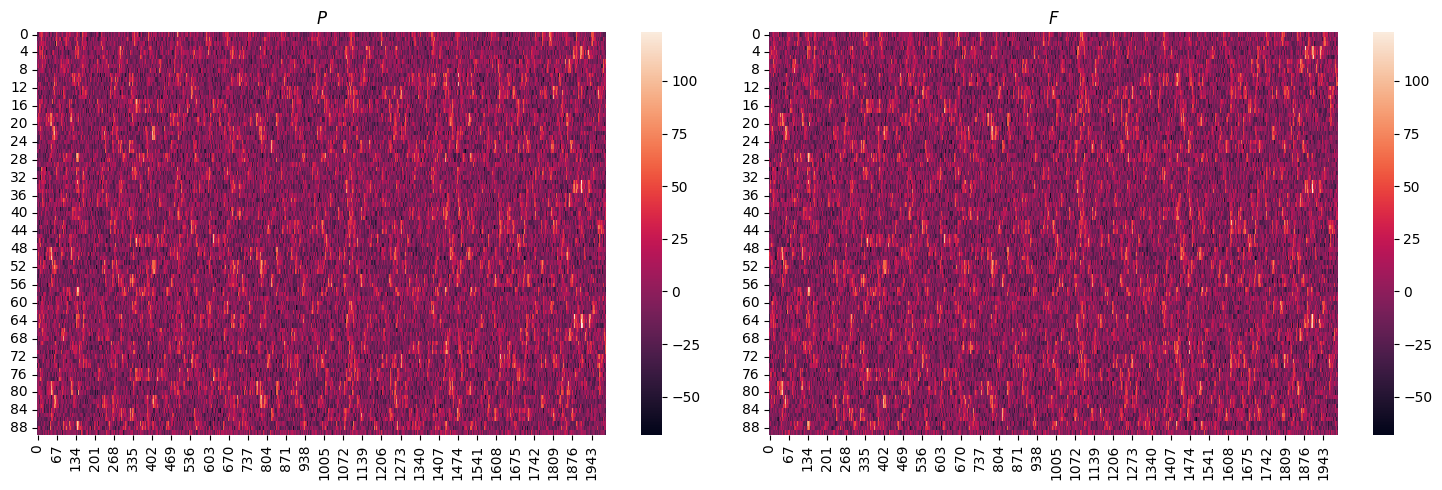

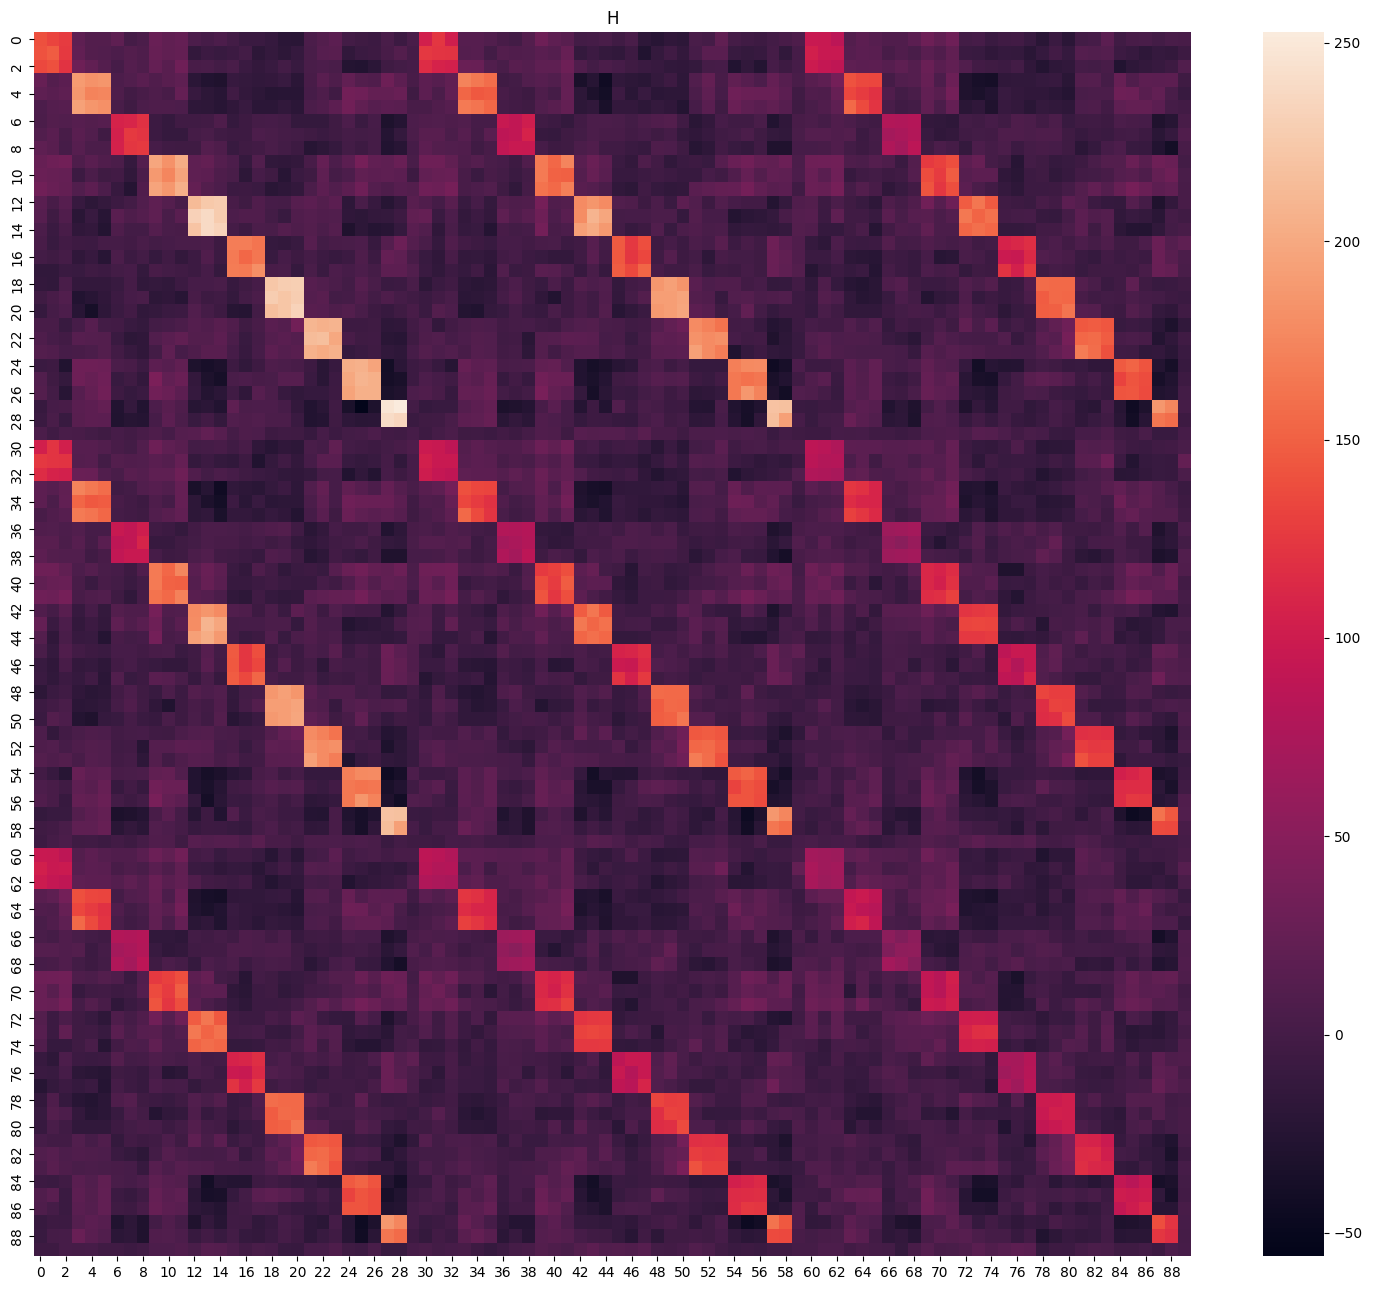

In [20]:
P_F_shape = (int(w / 2) * series.shape[0], n_timepoints - w)

P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(series.shape[0]):
    P[i::series.shape[0]] = Ps[i]
    F[i::series.shape[0]] = Fs[i]

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(P, ax=axs[0])
axs[0].set_title(f"$P$")

sns.heatmap(F, ax=axs[1])
axs[1].set_title(f"$F$")
fig.tight_layout()
plt.show()

H = (F @ P.T) / P.shape[1]

fig = plt.figure(figsize=(15, 13))
sns.heatmap(H, annot=False, fmt="0.1f")
plt.title("H")
fig.tight_layout()
plt.show()

In [21]:
from itertools import product

In [22]:
iterator = [tuple(reversed(ixs)) for ixs in product(*[range(0, int(w / 2) * series.shape[0], series.shape[0])]*2)]
iterator

[(0, 0),
 (30, 0),
 (60, 0),
 (0, 30),
 (30, 30),
 (60, 30),
 (0, 60),
 (30, 60),
 (60, 60)]

In [23]:
Hp = np.zeros((int(w / 2)**2, series.shape[0]**2))

for row_ix, (block_row_ix, block_col_ix) in enumerate(iterator):
    Hp[row_ix] = H[block_row_ix:block_row_ix + series.shape[0], block_col_ix:block_col_ix + series.shape[0]].ravel()

<Axes: >

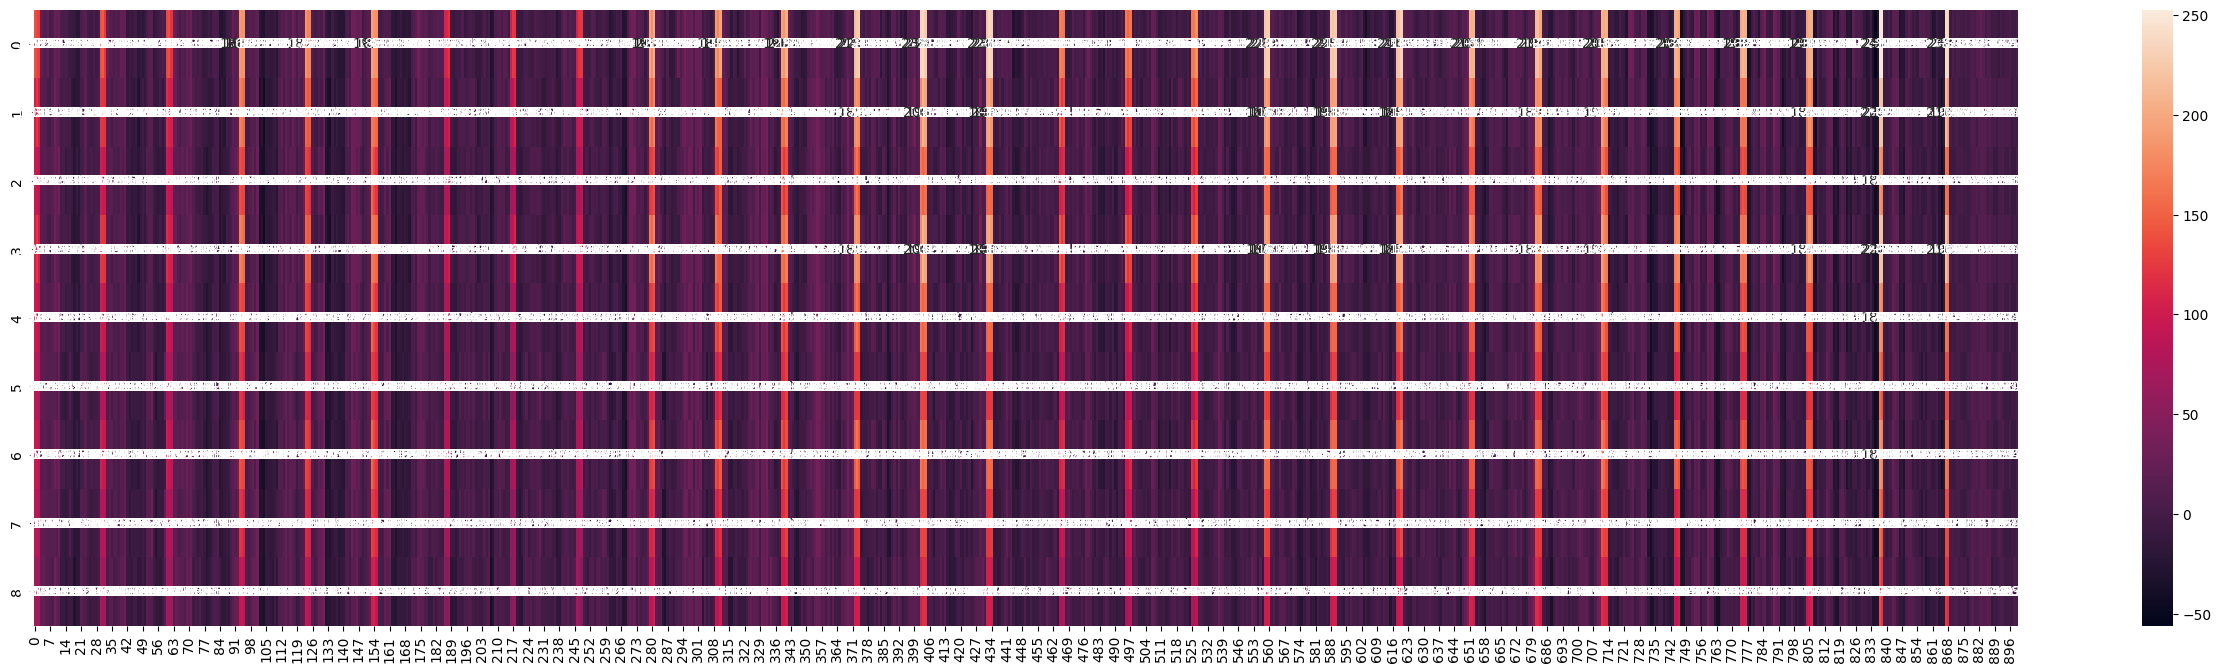

In [24]:
fig = plt.figure(figsize=(32, 8))

sns.heatmap(Hp, annot=True, fmt="0.1f")

In [25]:
u, s, v = linalg.svd(Hp)

Text(0.5, 1.0, 'V')

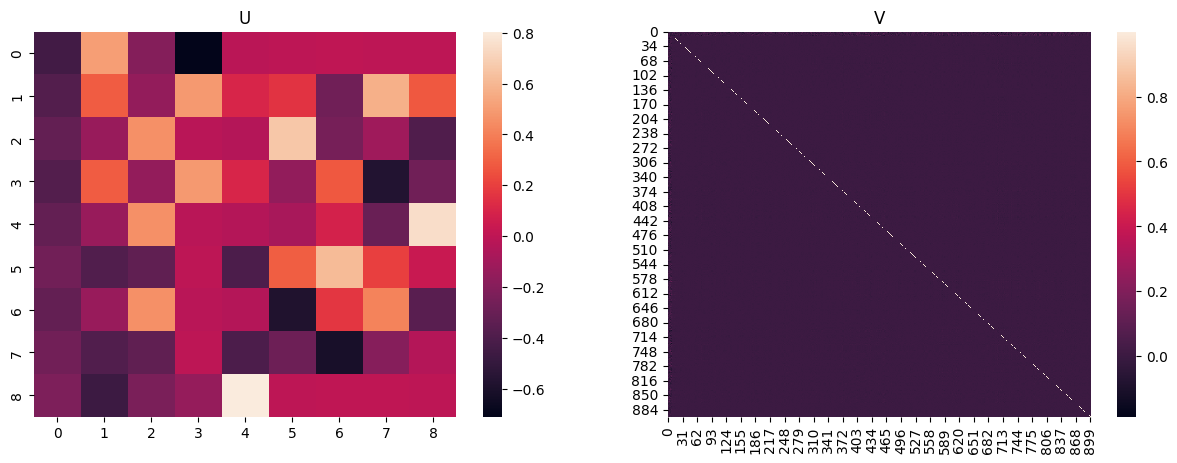

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(u, ax=axs[0])
axs[0].set_title("U")
sns.heatmap(v, ax=axs[1])
axs[1].set_title("V")

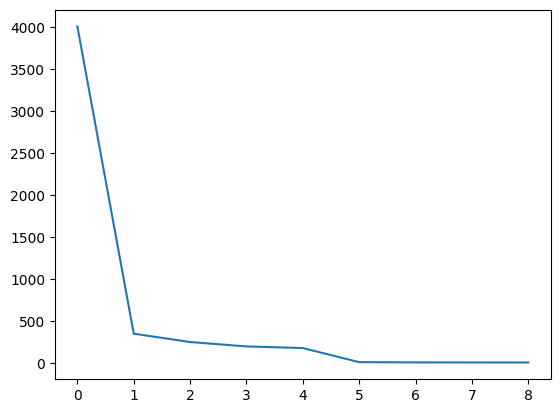

In [27]:
plt.plot(s)

Text(0.5, 1.0, '$V^r$')

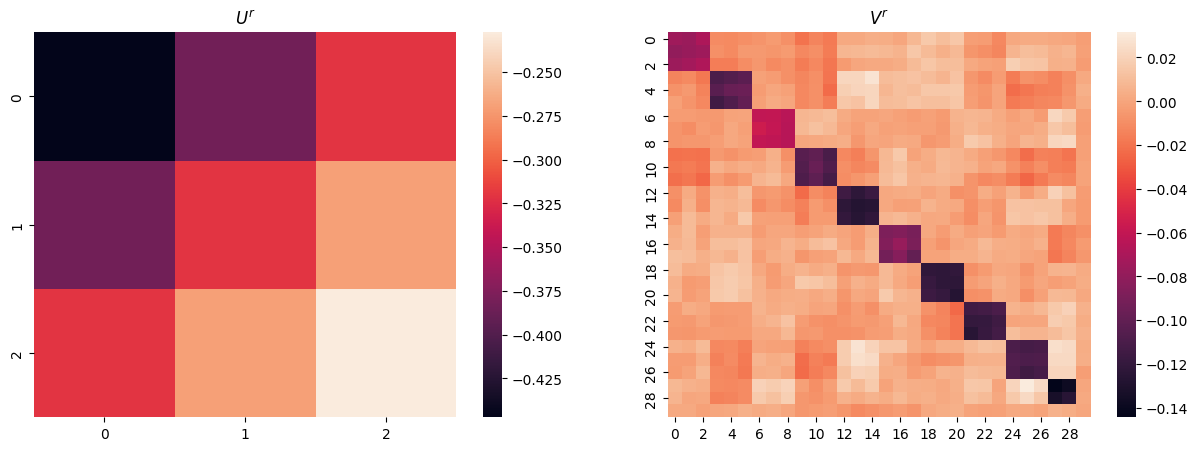

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
sns.heatmap(u_r, ax=axs[0])
axs[0].set_title("$U^r$")

v_r = v[0].reshape(series.shape[0], series.shape[0])
sns.heatmap(v_r, ax=axs[1])
axs[1].set_title("$V^r$")

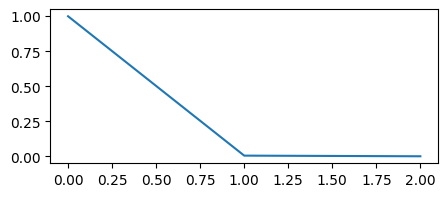

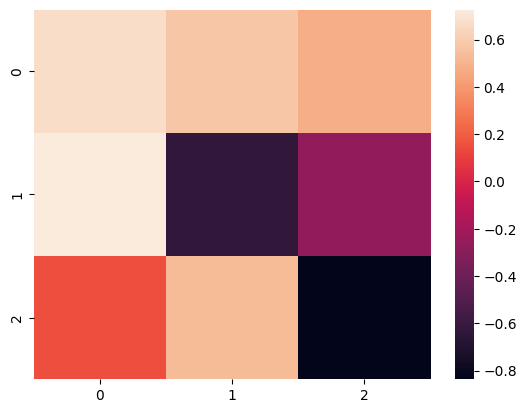

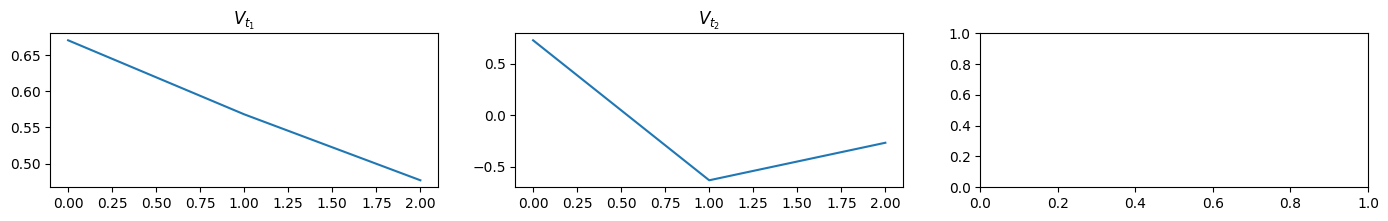

In [29]:
u_t, s_t, v_t = linalg.svd(u_r)

fig = plt.figure(figsize=(5, 2))
plt.plot(s_t)
plt.show()

sns.heatmap(v_t)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 2))

for i in range(2):
    axs[i].plot(v_t[i])
    axs[i].set_title(f"$V_{{t_{i + 1}}}$")
    
plt.show()

In [30]:
from sklearn.decomposition import SparsePCA

In [31]:
u_s, s_s, v_s = linalg.svd(v_r)

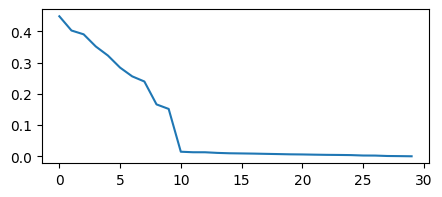

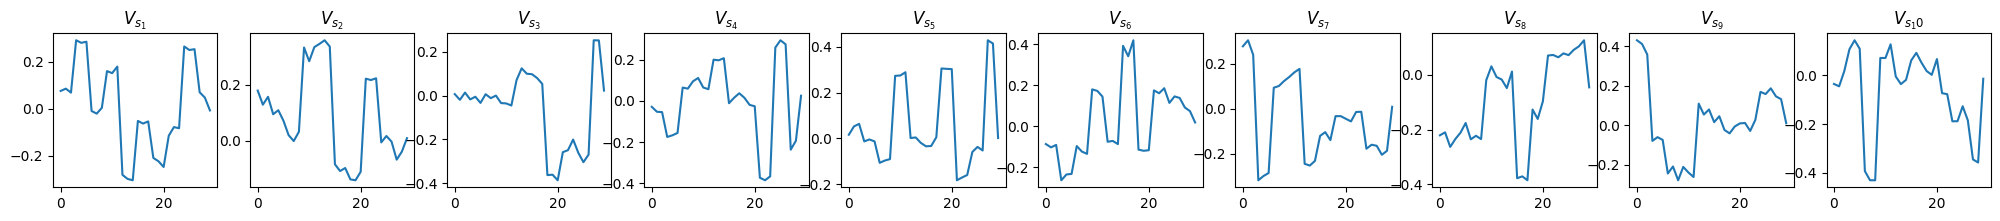

In [32]:
fig = plt.figure(figsize=(5, 2))
plt.plot(s_s)

fig, axs = plt.subplots(1, n_components, figsize=(25, 2))

for i in range(n_components):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [33]:
pca = SparsePCA(n_components=n_components, alpha=0.03, U_init=u_s, V_init=v_s)

u_s = pca.fit_transform(v_r)
v_s = pca.components_

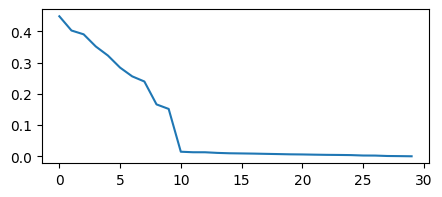

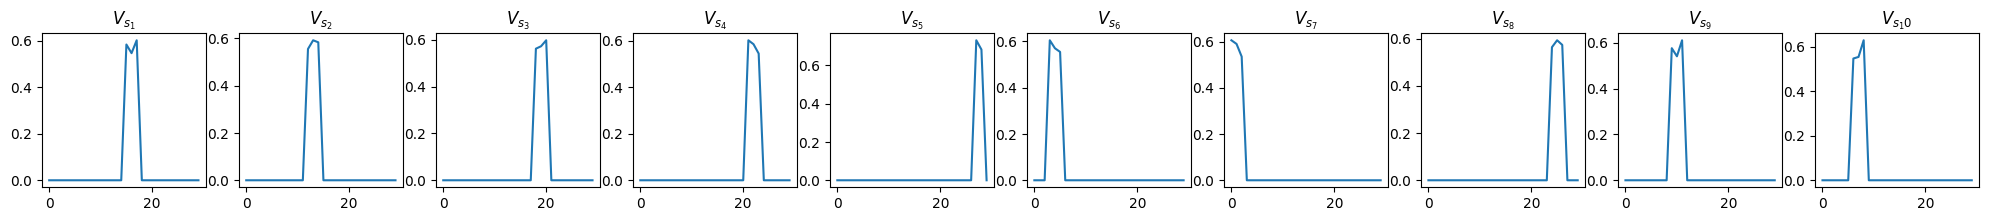

In [34]:
fig = plt.figure(figsize=(5, 2))
plt.plot(s_s)

fig, axs = plt.subplots(1, n_components, figsize=(25, 2))

for i in range(n_components):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

<Axes: >

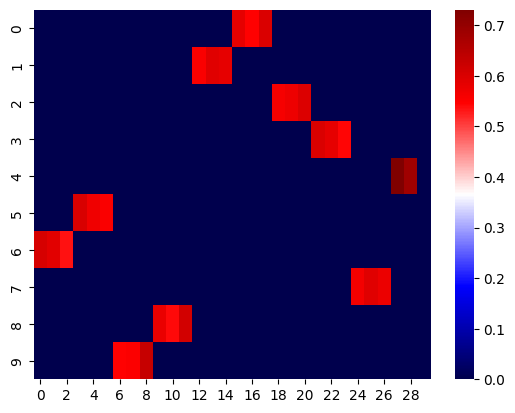

In [35]:
sns.heatmap(v_s[:n_components], cmap="seismic")

In [36]:
component_ixs = list()
for i in range(0, v_s.shape[1], int(w / 2)):
    component_ixs.append(np.abs(v_s[:, i]).argmax())

In [37]:
component_ixs

[6, 5, 9, 8, 1, 0, 2, 3, 7, 4]

In [38]:
v_s[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.58325498, 0.54600808, 0.60140569, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

In [39]:
filts = list()

for i in range(n_components):
    filts.append(np.kron(v_t[0], v_s[i]))

# Should be easier to interpret if I stack instead of interlace

In [40]:
filts = np.vstack(filts)

<Axes: >

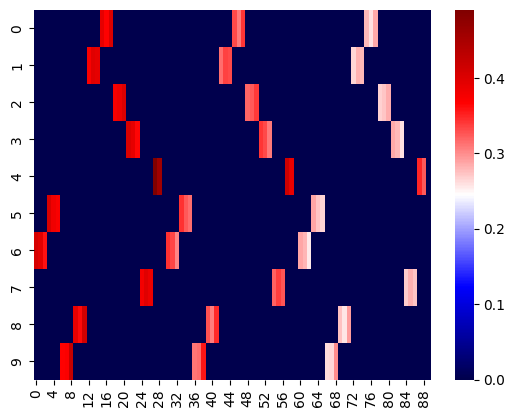

In [41]:
sns.heatmap(filts, cmap="seismic")

In [42]:
P.shape

(90, 1994)

In [43]:
v0 = -v0

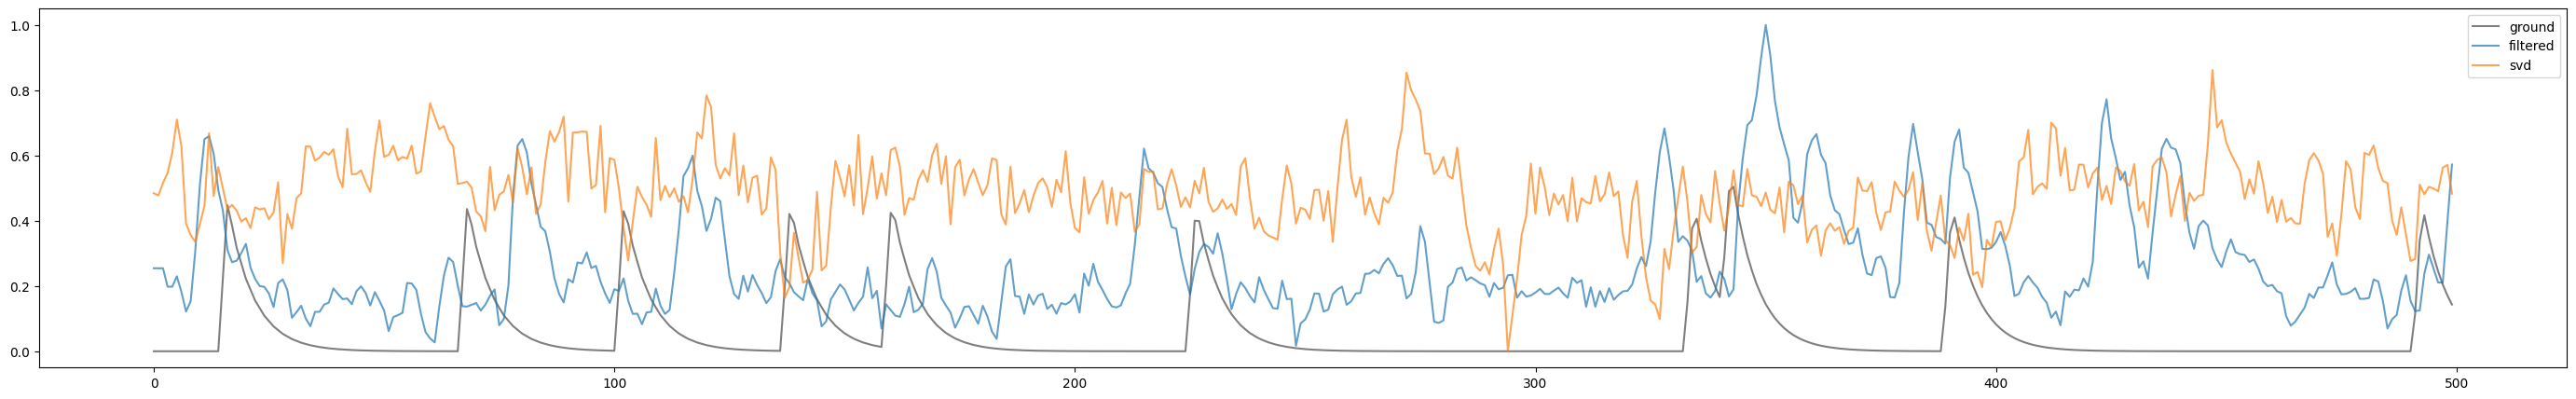

In [44]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filts[0] @ P
filtered = filtered

filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
v0 -= v0.min()
v0 /= v0.max()
plt.plot(v0[indices], label="svd", alpha=0.7)
# plt.plot(series[:3].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()

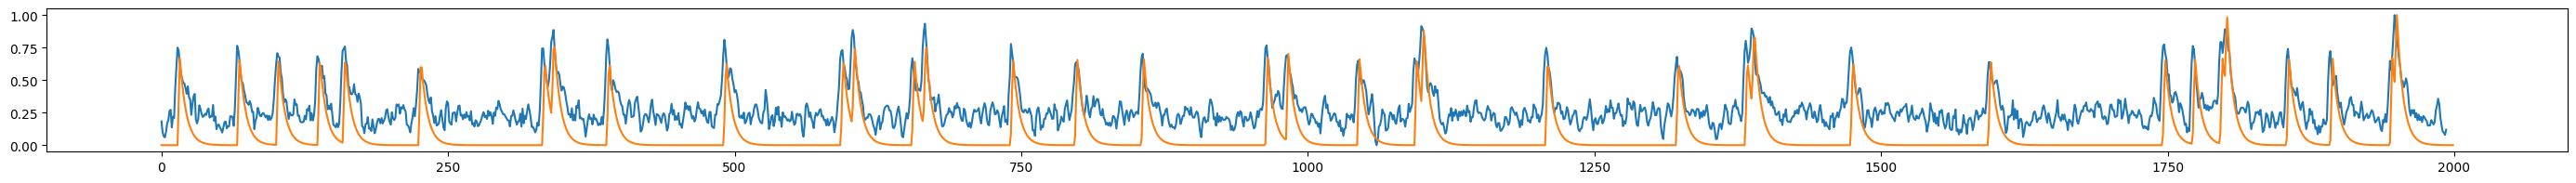

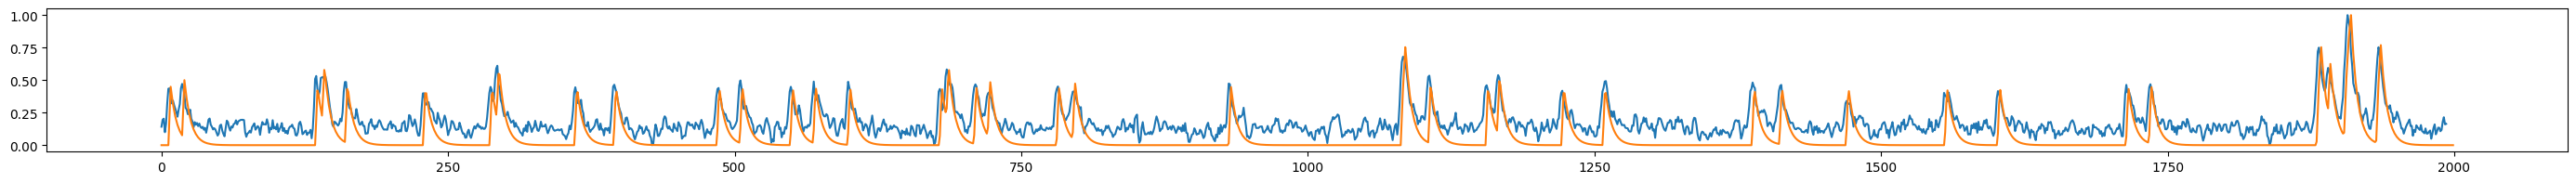

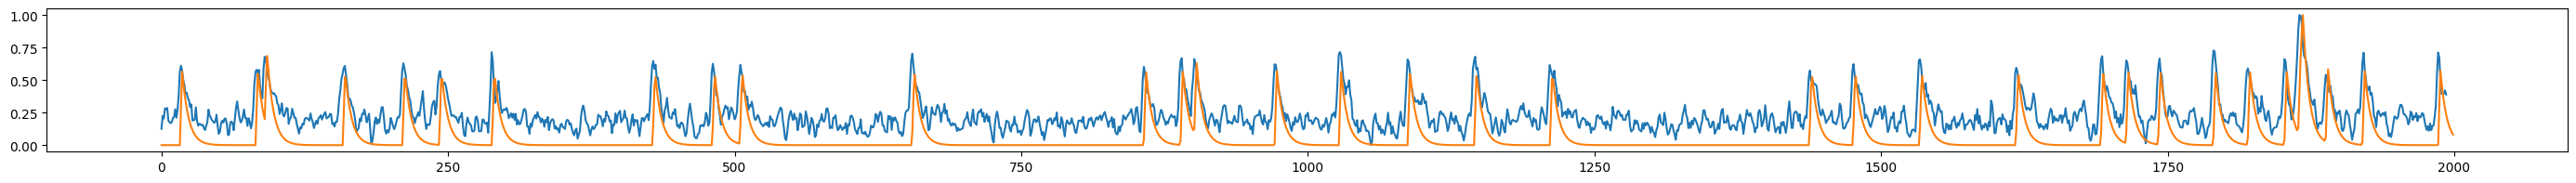

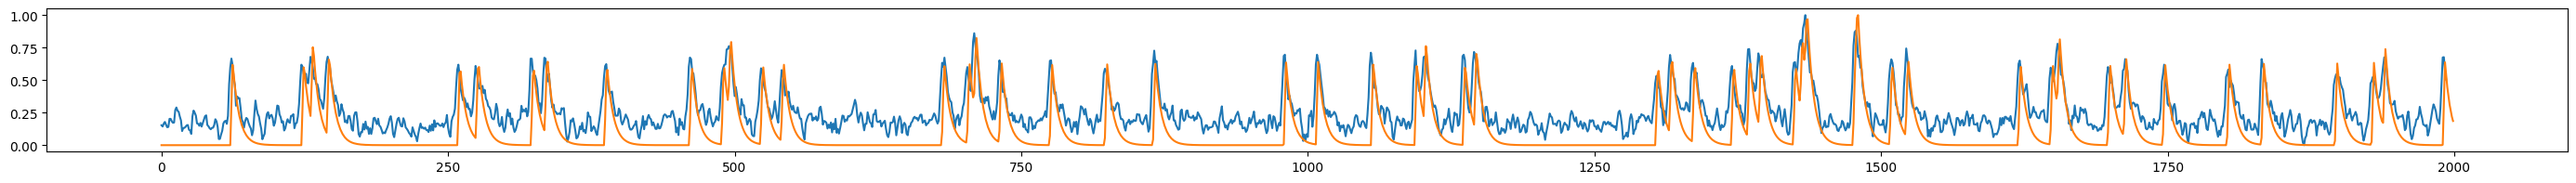

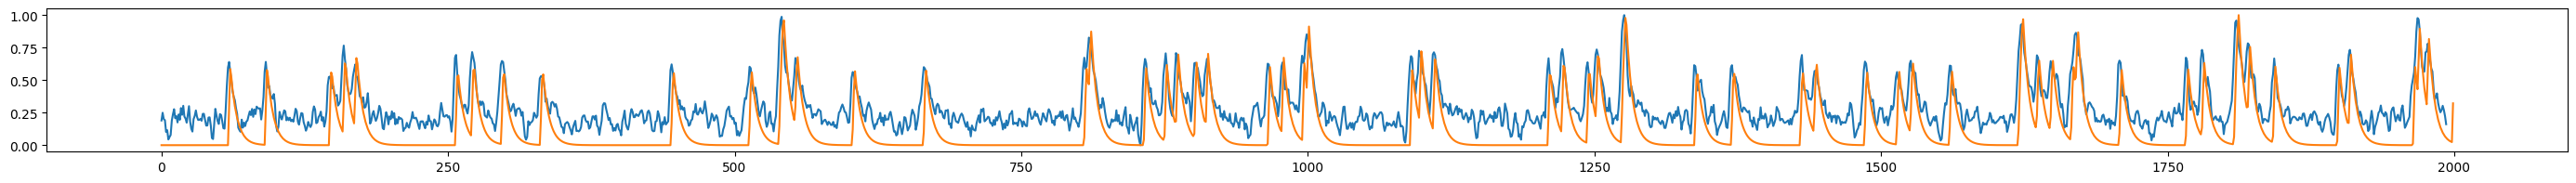

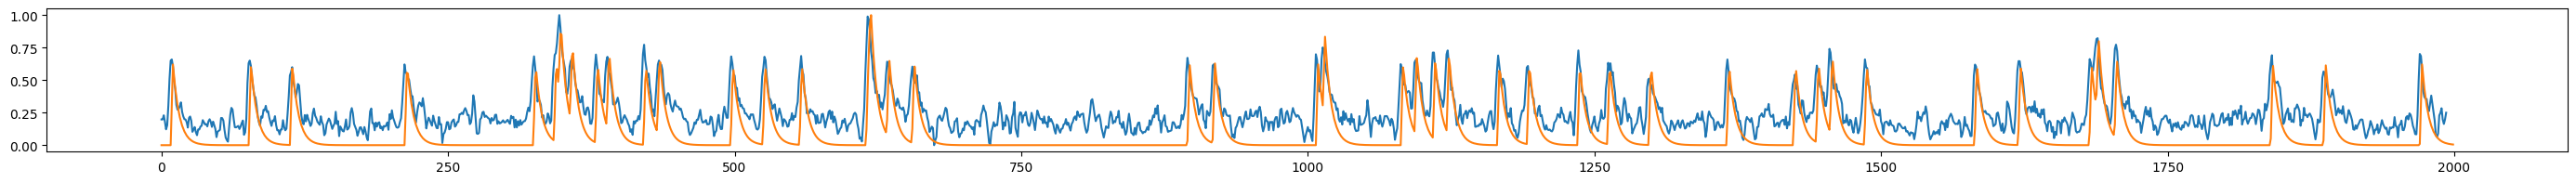

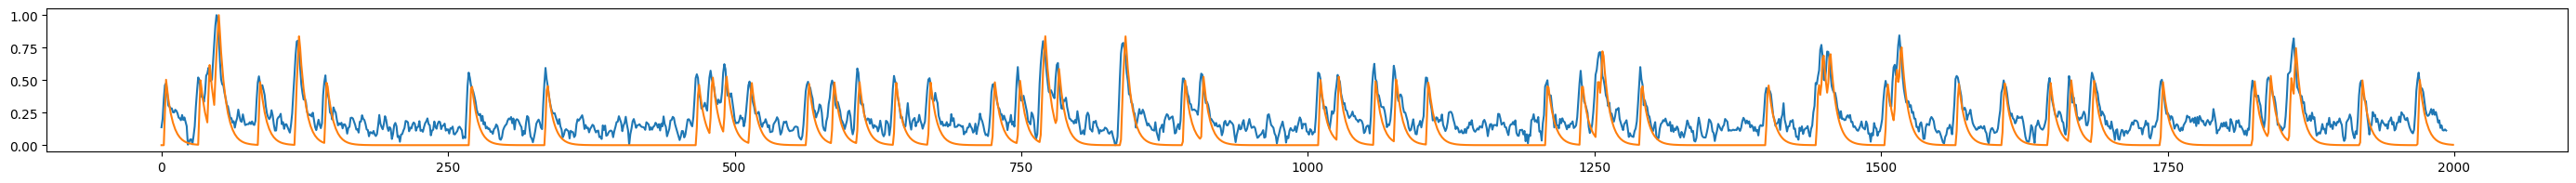

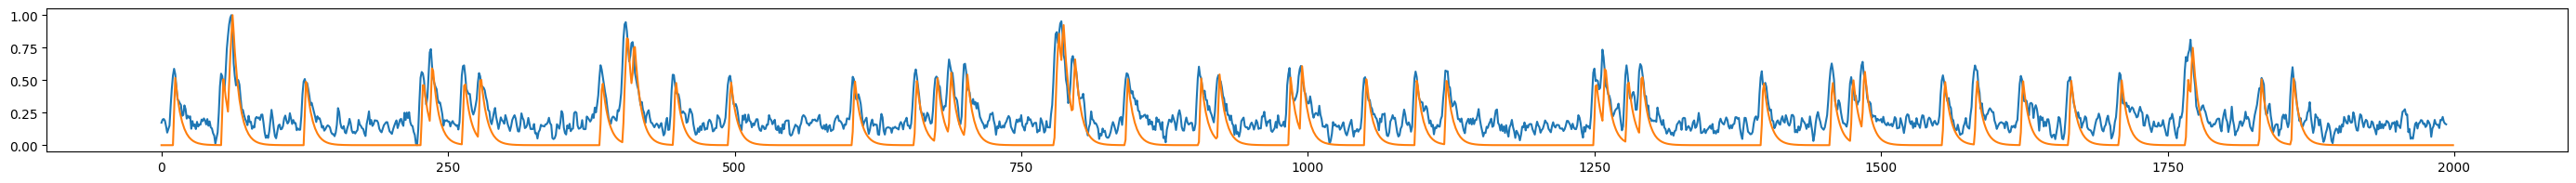

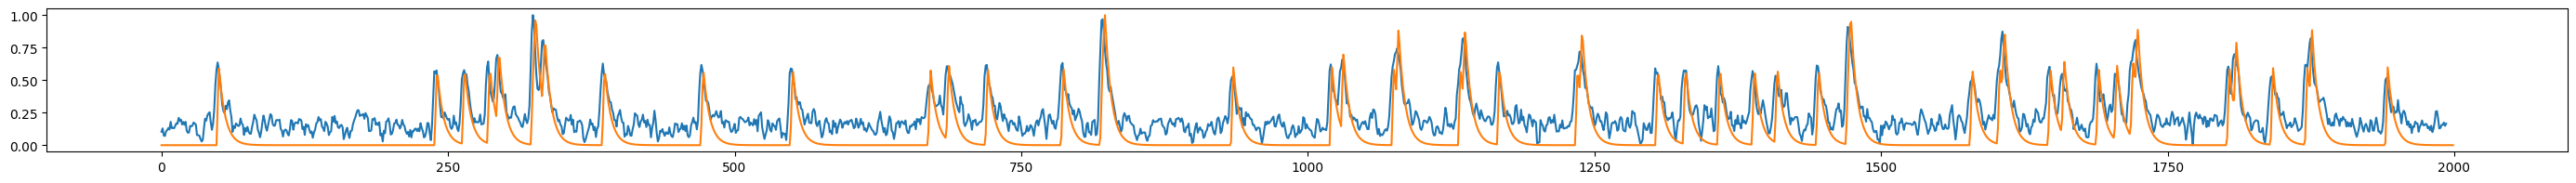

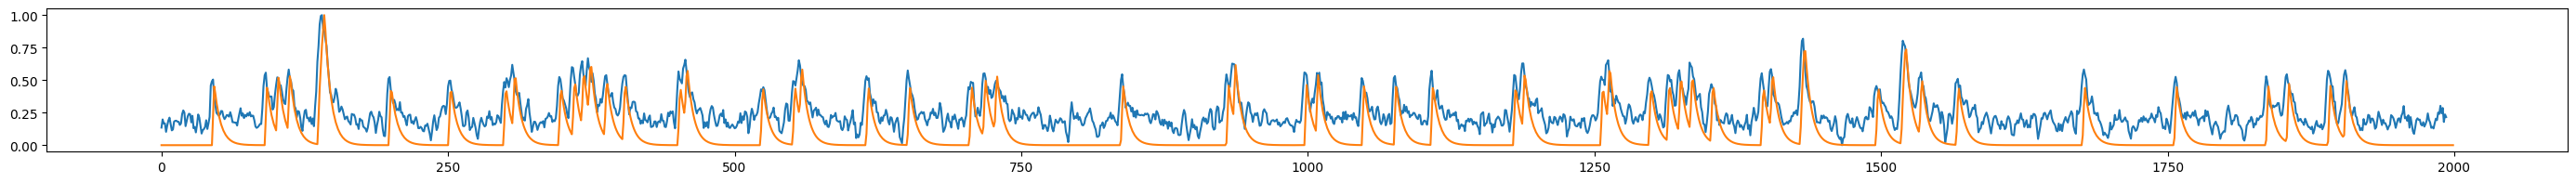

In [46]:
for i in range(n_components):
    filtered = filts[component_ixs[i]] @ P
    
    filtered -= filtered.min()
    filtered /= filtered.max()
    
    fig = plt.figure(figsize=(35, 2))
    plt.plot(filtered)
    plt.plot(clean[i] / clean[i].max())
    plt.show()

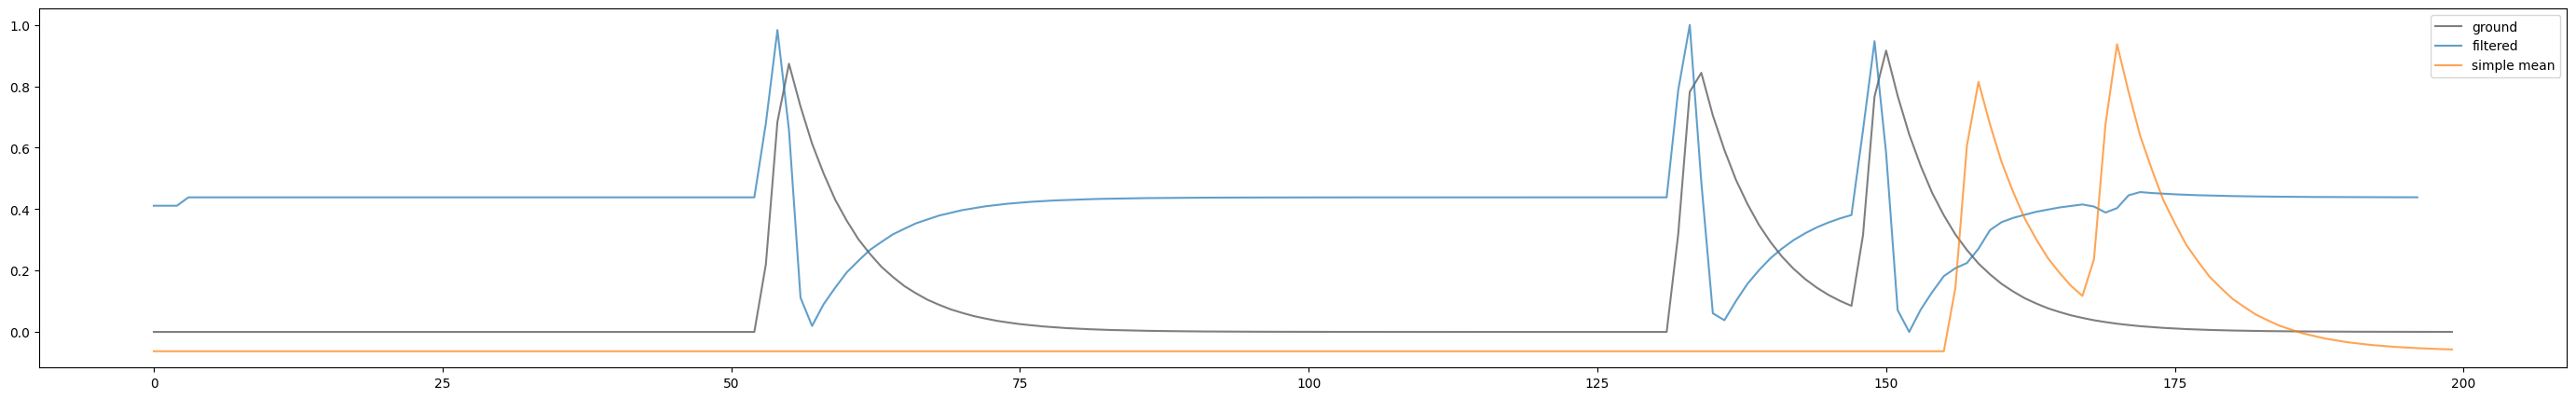

In [211]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filt2 @ P


filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
plt.plot(series[4:-1].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()